# 3. Modelo de Cox de riesgos proporcionales

El riesgo (*hazard*) es la tasa instantánea de **cierre**. HR > 1: la solicitud se cierra más rápido que la
referencia; HR < 1, más lento. Dos modelos (lifelines, muestra aleatoria fija de 200.000 solicitudes):

* **A (descriptivo):** agencia + borough + canal + fin de semana + franja nocturna.
* **B (equidad):** estratificado por tipo de queja (cada tipo con su propio riesgo base) + borough + canal + horario.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

from nyc311.config import ARCHIVO_LIMPIO, ARCHIVO_RESULTADOS, DIR_FIGURAS, DIR_TABLAS

res = json.loads(ARCHIVO_RESULTADOS.read_text(encoding="utf-8"))
tabla = lambda nombre: pd.read_csv(DIR_TABLAS / f"{nombre}.csv")
figura = lambda nombre: display(Image(filename=str(DIR_FIGURAS / nombre)))

In [2]:
cox = res["cox"]
print(f"Muestra: {cox['n_muestra']:,} solicitudes ({cox['eventos_muestra']:,} cierres)")
print(f"Concordancia A: {cox['modelo_A']['concordancia']:.3f} · B: {cox['modelo_B']['concordancia']:.3f}")
tabla("cox_modelo_A")

Muestra: 200,000 solicitudes (194,628 cierres)
Concordancia A: 0.755 · B: 0.542


,covariable,hr,ic_inf,ic_sup,p_valor,lectura
0,fin_de_semana,1.014,1.004,1.024,0.008,"en cada momento, 1 % más probable cerrarse (má..."
1,nocturna,1.092,1.080,1.104,0.000,"en cada momento, 9 % más probable cerrarse (má..."
2,agencia=DEP,0.111,0.108,0.113,0.000,"en cada momento, 89 % menos probable cerrarse ..."
3,agencia=DHS,0.135,0.129,0.141,0.000,"en cada momento, 87 % menos probable cerrarse ..."
4,agencia=DOB,0.045,0.044,0.047,0.000,"en cada momento, 95 % menos probable cerrarse ..."
5,agencia=DOHMH,0.045,0.044,0.047,0.000,"en cada momento, 95 % menos probable cerrarse ..."
6,agencia=DOT,0.075,0.074,0.077,0.000,"en cada momento, 92 % menos probable cerrarse ..."
7,agencia=DPR,0.028,0.027,0.029,0.000,"en cada momento, 97 % menos probable cerrarse ..."
8,agencia=DSNY,0.116,0.114,0.118,0.000,"en cada momento, 88 % menos probable cerrarse ..."
9,agencia=HPD,0.059,0.058,0.060,0.000,"en cada momento, 94 % menos probable cerrarse ..."


In [3]:
tabla('cox_modelo_B')

,covariable,hr,ic_inf,ic_sup,p_valor,lectura
0,fin_de_semana,0.982,0.972,0.992,0.001,"en cada momento, 2 % menos probable cerrarse (..."
1,nocturna,1.058,1.046,1.070,0.000,"en cada momento, 6 % más probable cerrarse (má..."
2,borough=BRONX,0.867,0.854,0.880,0.000,"en cada momento, 13 % menos probable cerrarse ..."
3,borough=BROOKLYN,0.940,0.928,0.953,0.000,"en cada momento, 6 % menos probable cerrarse (..."
4,borough=QUEENS,0.909,0.896,0.922,0.000,"en cada momento, 9 % menos probable cerrarse (..."
5,borough=STATEN ISLAND,1.037,1.011,1.063,0.005,"en cada momento, 4 % más probable cerrarse (má..."
6,canal=App móvil,0.961,0.947,0.975,0.000,"en cada momento, 4 % menos probable cerrarse (..."
7,canal=Otro/desconocido,0.791,0.773,0.811,0.000,"en cada momento, 21 % menos probable cerrarse ..."
8,canal=Web,1.041,1.029,1.053,0.000,"en cada momento, 4 % más probable cerrarse (má..."


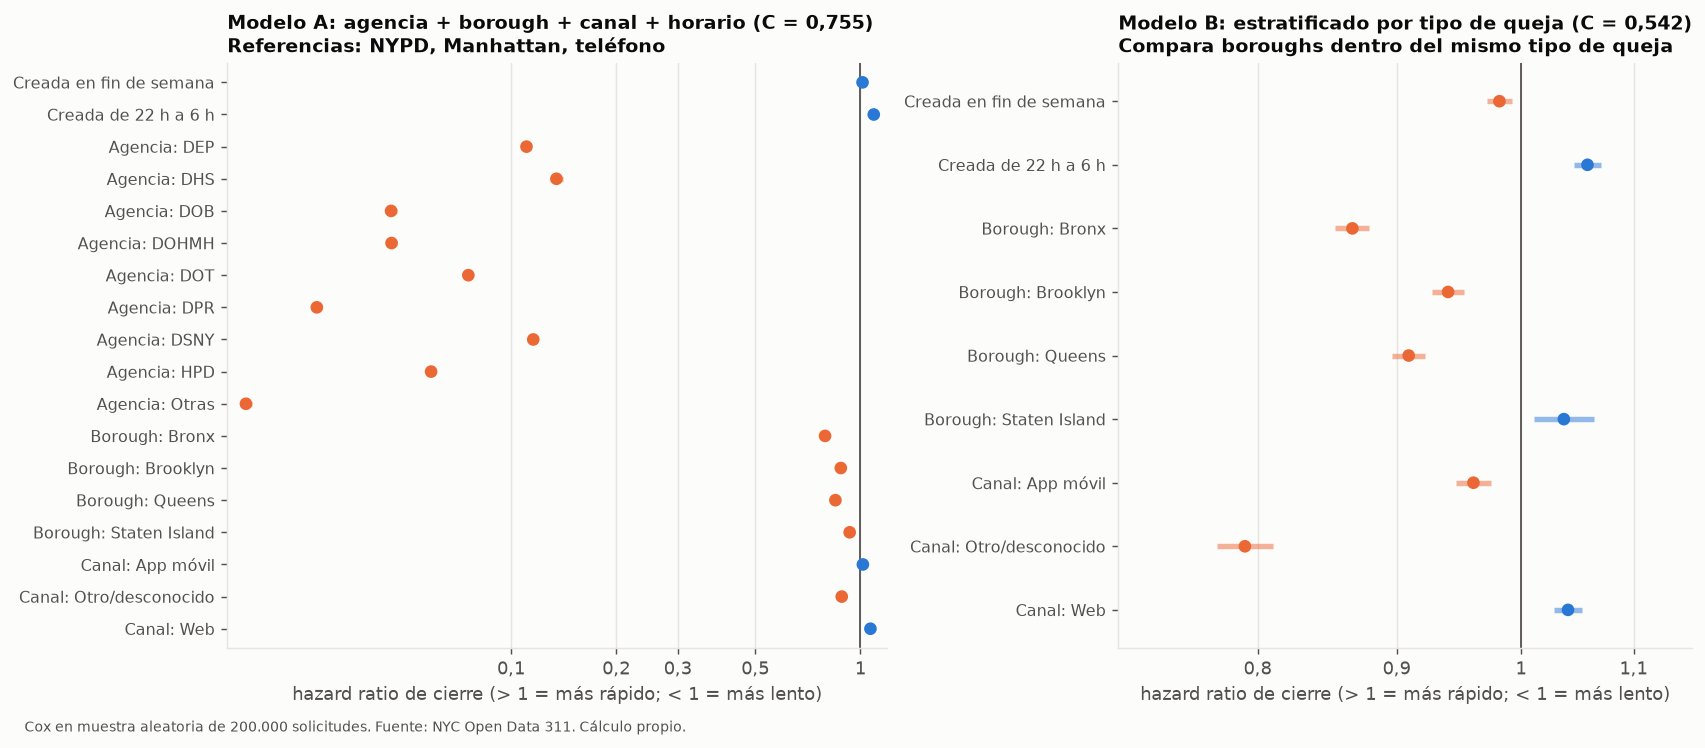

In [4]:
figura("06_cox_hazard_ratios.png")

## 3.1 Cómo se ajusta (demostración en una muestra pequeña)

El pipeline usa 200.000 filas; aquí 30.000 para que el notebook corra rápido. Los HR deben parecerse.

In [5]:
from nyc311 import cox as mcox
df = pd.read_parquet(ARCHIVO_LIMPIO)
muestra = mcox.muestra_modelo(df, n=30_000)
del df
cph = mcox.ajustar(mcox.matriz_modelo(muestra, "B"), "B")
cph.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]]

,exp(coef),exp(coef) lower 95%,exp(coef) upper 95%,p
covariate,,,,
fin_de_semana,0.990,0.964,1.016,0.446
nocturna,1.063,1.031,1.095,0.000
borough=BRONX,0.865,0.833,0.898,0.000
borough=BROOKLYN,0.946,0.914,0.979,0.002
borough=QUEENS,0.911,0.878,0.945,0.000
borough=STATEN ISLAND,1.059,0.993,1.129,0.079
canal=App móvil,0.989,0.953,1.027,0.578
canal=Otro/desconocido,0.806,0.758,0.857,0.000
canal=Web,1.058,1.026,1.090,0.000


## 3.2 ¿Se cumple el supuesto de riesgos proporcionales?

Cox supone que el HR es constante en el tiempo. Tres comprobaciones:

1. **Prueba de Grambsch-Therneau** (residuos de Schoenfeld escalados, tiempo en rangos) en 40.000 filas.
2. **Curvas log(−log S)** por borough: con PH serían paralelas.
3. **HR por ventana de tiempo**: reajustar el modelo B solo con las solicitudes aún abiertas al inicio de cada
   ventana (0–1 día, 1–7, 7–30, > 30). Si el HR cambia mucho, el HR global es un promedio que esconde dinámica.

In [6]:
tabla('supuesto_ph_modelo_A').head(10)

,covariable,estadistico,p_valor
0,agencia=DEP,407.268,0.000
1,canal=Otro/desconocido,347.479,0.000
2,agencia=DOHMH,274.366,0.000
3,borough=BRONX,118.031,0.000
4,agencia=DHS,111.239,0.000
5,borough=BROOKLYN,89.490,0.000
6,borough=QUEENS,54.875,0.000
7,borough=STATEN ISLAND,48.666,0.000
8,agencia=DPR,46.462,0.000
9,agencia=DOB,38.353,0.000


In [7]:
tabla('supuesto_ph_modelo_B')

,covariable,estadistico,p_valor
0,borough=BRONX,21.478,0.000
1,borough=BROOKLYN,17.893,0.000
2,nocturna,10.729,0.001
3,borough=STATEN ISLAND,10.703,0.001
4,canal=Otro/desconocido,6.471,0.011
5,canal=Web,5.903,0.015
6,canal=App móvil,5.792,0.016
7,borough=QUEENS,5.114,0.024
8,fin_de_semana,0.042,0.837


In [8]:
v = tabla("cox_hr_por_ventana")
v.loc[v["covariable"].str.startswith("borough"), ["ventana", "covariable", "hr", "ic_inf", "ic_sup", "n_en_riesgo"]]

,ventana,covariable,hr,ic_inf,ic_sup,n_en_riesgo
2,0–1 d,borough=BRONX,0.674,0.651,0.698,60000
3,0–1 d,borough=BROOKLYN,0.828,0.802,0.855,60000
4,0–1 d,borough=QUEENS,0.808,0.782,0.836,60000
5,0–1 d,borough=STATEN ISLAND,0.864,0.814,0.918,60000
11,1–7 d,borough=BRONX,1.076,1.021,1.134,24541
12,1–7 d,borough=BROOKLYN,0.974,0.928,1.023,24541
13,1–7 d,borough=QUEENS,0.981,0.930,1.036,24541
14,1–7 d,borough=STATEN ISLAND,1.288,1.181,1.404,24541
20,7–30 d,borough=BRONX,1.293,1.194,1.401,11160
21,7–30 d,borough=BROOKLYN,1.186,1.099,1.279,11160


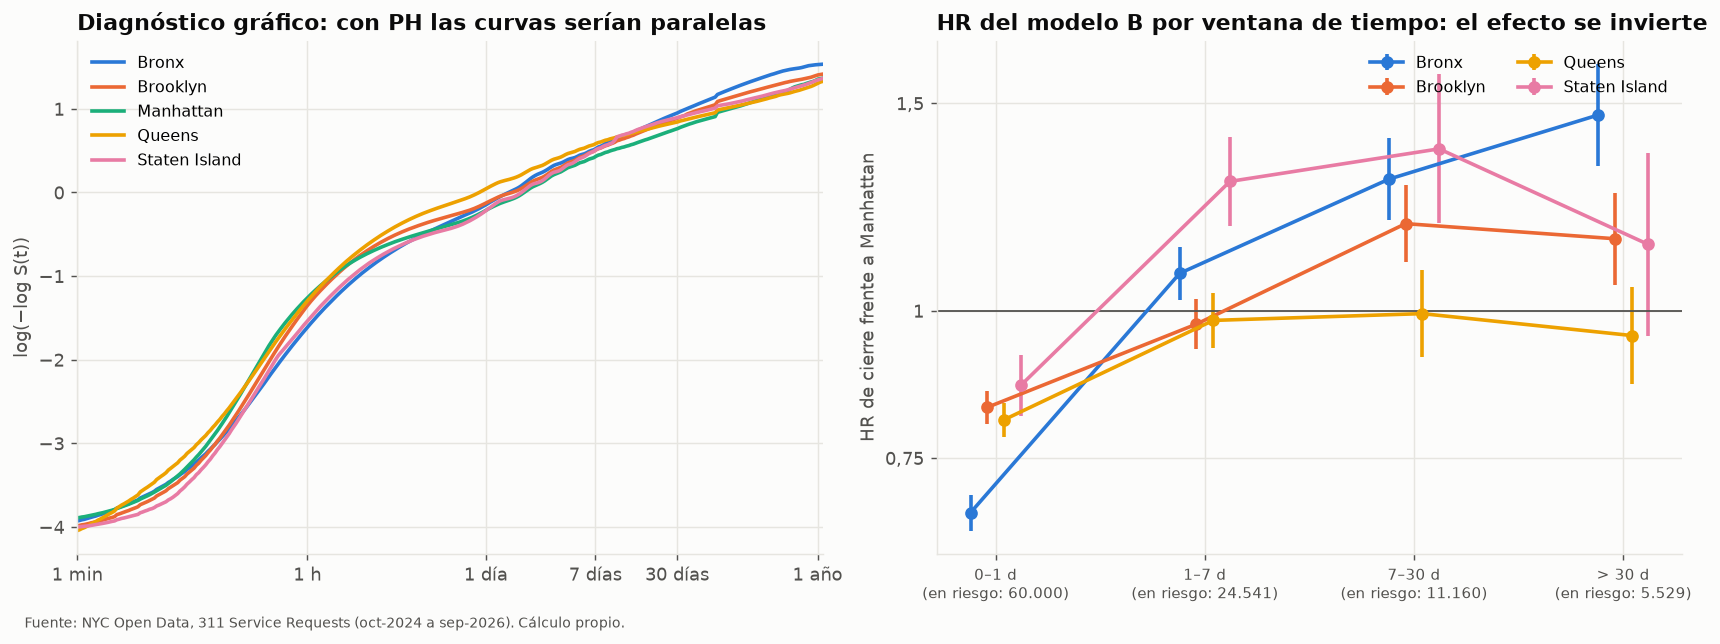

In [9]:
figura("07_supuesto_riesgos_proporcionales.png")

**Conclusión sobre PH.** El supuesto **no se cumple** para agencia (por eso el modelo B estratifica por tipo de
queja en lugar de estimar un HR por agencia) ni del todo para borough: el Bronx cierra mucho más lento durante el
primer día y, entre las que siguen abiertas tras una semana, cierra más rápido que Manhattan. El HR global del
modelo B debe leerse como un **promedio ponderado en el tiempo**, dominado por las primeras horas, donde ocurre
la mayoría de los cierres. Por eso el análisis de equidad se complementa con una medida sin supuesto PH (O/E a 7 días).

## 3.3 Lectura en lenguaje de negocio

In [10]:
for fila in res["cox"]["modelo_B"]["hr"]:
    print(f"{fila['covariable']:<26} HR {fila['hr']:.2f} → {fila['lectura']}")

fin_de_semana              HR 0.98 → en cada momento, 2 % menos probable cerrarse (más lento)
nocturna                   HR 1.06 → en cada momento, 6 % más probable cerrarse (más rápido)
borough=BRONX              HR 0.87 → en cada momento, 13 % menos probable cerrarse (más lento)
borough=BROOKLYN           HR 0.94 → en cada momento, 6 % menos probable cerrarse (más lento)
borough=QUEENS             HR 0.91 → en cada momento, 9 % menos probable cerrarse (más lento)
borough=STATEN ISLAND      HR 1.04 → en cada momento, 4 % más probable cerrarse (más rápido)
canal=App móvil            HR 0.96 → en cada momento, 4 % menos probable cerrarse (más lento)
canal=Otro/desconocido     HR 0.79 → en cada momento, 21 % menos probable cerrarse (más lento)
canal=Web                  HR 1.04 → en cada momento, 4 % más probable cerrarse (más rápido)
